# Model Evaluation and Comparison

**Author:** Niyaz

Goal: compare all regression models developed by the team under **one evaluation protocol**, check overfitting and underfitting, and collect the evidence for choosing the final model.

| Model | Source notebook | Hyperparameters |
|---|---|---|
| Linear Regression | `01_data_preprocessing.ipynb` (Dariya) | none to tune |
| Decision Tree (baseline, tuned) | `02_decision_tree.ipynb` (Bakai) | Grid Search result |
| Random Forest (baseline, tuned, tuned + FE) | `03_random_forest.ipynb` (Rimma) | Grid Search result |
| Gradient Boosting (baseline, tuned, tuned + log target) | `04_gradient_boosting.ipynb` (Niyaz) | Grid Search result |

Every model is retrained here with exactly the same pipeline as in its source notebook. The saved results files cannot be compared directly: they use different columns, and Linear Regression has no CV RMSE. Retraining also checks that the reported numbers are reproducible (section 4).

## 1. Evaluation protocol

- **Split:** the shared 80/20 hold-out from `01_data_preprocessing.ipynb` (`random_state=42`): 5,918 training rows, 1,480 validation rows.
- **CV RMSE (primary selection metric):** 5-fold `KFold(shuffle=True, random_state=42)` on the training part, the same folds the Grid Searches used. Reported as mean and standard deviation over the folds.
- **Validation RMSE:** the model is refit on the full training part and scored once on the validation set. No notebook used this set for tuning, so it serves as an independent check of the CV estimate.
- **Train RMSE:** the same refit model scored on its own training data. Train vs CV vs validation shows overfitting or underfitting.
- **Secondary metrics:** validation MAE and R², fit time, model size.
- `challenge1_test.csv` is not used in this notebook.

In [1]:
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullLocator, StrMethodFormatter

from sklearn.model_selection import train_test_split, KFold, learning_curve
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

train_df = pd.read_csv("../data/challenge1_train.csv")

X = train_df.drop(columns=["price", "ID"])
y = train_df["price"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print(f"Price: mean {y.mean():,.0f}, std {y.std():,.0f}, max {y.max():,.0f}")

X_train: (5918, 8) | X_val: (1480, 8)
Price: mean 1,463, std 822, max 8,800


## 2. Candidate models

Preprocessing is model-specific and copied from the source notebooks:

- **Linear Regression and Decision Tree** use the shared preprocessor: `StandardScaler` for numeric features and one-hot encoding for `category`, `has_photo`, `state`. Scaling matters for linear models only; it does not change tree splits but is kept for the Decision Tree to reproduce `02` exactly.
- **Random Forest and Gradient Boosting** pass numeric features through unscaled and one-hot encode the categoricals (`03`, `04`).
- **Gradient Boosting (tuned + log target)** is trained on `log(price)` through `TransformedTargetRegressor` and converts predictions back with `exp` (`04`).
- **Random Forest (tuned + FE)** adds the four engineered features from `03`: space per bedroom and per bathroom, total rooms, latitude × longitude.
- **Mean baseline** (`DummyRegressor`) always predicts the training mean. Its RMSE is roughly the standard deviation of the price, and any useful model must clearly beat it.

`handle_unknown="ignore"` matters because the test set contains a state (WY) that never appears in the training data.

In [2]:
numeric_features = ["bathrooms", "bedrooms", "square_feet", "latitude", "longitude"]
categorical_features = ["category", "has_photo", "state"]
engineered_features = ["sqft_per_bedroom", "sqft_per_bathroom", "total_rooms", "lat_lon_interaction"]


def scaled_preprocessor():
    # shared preprocessor from 01_data_preprocessing.ipynb (also used in 02)
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])


def tree_preprocessor(num_features=numeric_features):
    # 03_random_forest.ipynb: trees do not need scaling
    return ColumnTransformer([
        ("num", "passthrough", num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])


def add_features(df):
    # same as 03_random_forest.ipynb, section 5; uses only each row's own values
    df = df.copy()
    df["sqft_per_bedroom"] = df["square_feet"] / (df["bedrooms"] + 1)
    df["sqft_per_bathroom"] = df["square_feet"] / df["bathrooms"].clip(lower=0.5)
    df["total_rooms"] = df["bedrooms"] + df["bathrooms"]
    df["lat_lon_interaction"] = df["latitude"] * df["longitude"]
    return df


def no_features(df):
    return df


# Grid Search results from the source notebooks
DT_TUNED = {"max_depth": 15, "min_samples_leaf": 5, "min_samples_split": 2, "ccp_alpha": 50.0}   # 02
RF_TUNED = {"n_estimators": 400, "max_depth": 20, "min_samples_leaf": 1, "max_features": 0.33}  # 03
GB_TUNED = {"n_estimators": 1000, "learning_rate": 0.1, "max_depth": 5, "min_samples_leaf": 5,
            "subsample": 1.0, "max_features": 0.5}                                                # 04, raw target
GB_LOG_TUNED = {**GB_TUNED, "subsample": 0.8}                                                 # 04, log target


@dataclass
class Candidate:
    name: str
    family: str
    source: str
    build: Callable[[], Pipeline]  # returns a fresh, unfitted pipeline
    features: Callable[[pd.DataFrame], pd.DataFrame] = no_features


candidates = [
    Candidate("Mean baseline", "Reference", "05_model_comparison",
              lambda: Pipeline([("prep", scaled_preprocessor()), ("model", DummyRegressor())])),
    Candidate("Linear Regression", "Linear Regression", "01_data_preprocessing",
              lambda: Pipeline([("prep", scaled_preprocessor()), ("model", LinearRegression())])),
    Candidate("Decision Tree (baseline)", "Decision Tree", "02_decision_tree",
              lambda: Pipeline([("prep", scaled_preprocessor()),
                                ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))])),
    Candidate("Decision Tree (tuned)", "Decision Tree", "02_decision_tree",
              lambda: Pipeline([("prep", scaled_preprocessor()),
                                ("model", DecisionTreeRegressor(random_state=RANDOM_STATE, **DT_TUNED))])),
    Candidate("Random Forest (baseline)", "Random Forest", "03_random_forest",
              lambda: Pipeline([("prep", tree_preprocessor()),
                                ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])),
    Candidate("Random Forest (tuned)", "Random Forest", "03_random_forest",
              lambda: Pipeline([("prep", tree_preprocessor()),
                                ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **RF_TUNED))])),
    Candidate("Random Forest (tuned + FE)", "Random Forest", "03_random_forest",
              lambda: Pipeline([("prep", tree_preprocessor(numeric_features + engineered_features)),
                                ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **RF_TUNED))]),
              features=add_features),
    Candidate("Gradient Boosting (baseline)", "Gradient Boosting", "04_gradient_boosting",
              lambda: Pipeline([("prep", tree_preprocessor()),
                                ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])),
    Candidate("Gradient Boosting (tuned)", "Gradient Boosting", "04_gradient_boosting",
              lambda: Pipeline([("prep", tree_preprocessor()),
                                ("model", GradientBoostingRegressor(random_state=RANDOM_STATE, **GB_TUNED))])),
    Candidate("Gradient Boosting (tuned + log target)", "Gradient Boosting", "04_gradient_boosting",
              lambda: Pipeline([("prep", tree_preprocessor()),
                                ("model", TransformedTargetRegressor(
                                    regressor=GradientBoostingRegressor(random_state=RANDOM_STATE, **GB_LOG_TUNED),
                                    func=np.log, inverse_func=np.exp))])),
]

## 3. Evaluate every candidate

`evaluate` applies the protocol from section 1 to one candidate. A fresh pipeline is built for every fold, so the preprocessor is fit on the training folds only (no leakage). Besides the scores it keeps the **out-of-fold predictions** (one prediction for each of the 5,918 training rows, made by the model that did not see that row) and the validation predictions; sections 5 and 7 use them for paired comparisons and error analysis.

In [3]:
def complexity(model):
    est = model.named_steps["model"]
    est = getattr(est, "regressor_", est)  # unwrap the log-target wrapper
    if isinstance(est, DummyRegressor):
        return "1 constant"
    if hasattr(est, "coef_"):
        return f"{est.coef_.size} coefficients"
    if hasattr(est, "get_n_leaves"):
        return f"1 tree, {est.get_n_leaves():,} leaves"
    trees = np.ravel(est.estimators_)  # Random Forest: list of trees, Gradient Boosting: 2D array
    return f"{len(trees)} trees, {sum(t.get_n_leaves() for t in trees):,} leaves"


def evaluate(c):
    X_tr, X_va = c.features(X_train), c.features(X_val)

    # 5-fold CV on the training part: per-fold RMSE and out-of-fold predictions
    fold_rmse, oof_pred = [], np.zeros(len(y_train))
    for tr_idx, va_idx in cv.split(X_tr):
        fold_model = c.build().fit(X_tr.iloc[tr_idx], y_train.iloc[tr_idx])
        oof_pred[va_idx] = fold_model.predict(X_tr.iloc[va_idx])
        fold_rmse.append(rmse(y_train.iloc[va_idx], oof_pred[va_idx]))

    # refit on the whole training part, then score on train and on the validation set
    t0 = time.perf_counter()
    model = c.build().fit(X_tr, y_train)
    fit_time = time.perf_counter() - t0
    val_pred = model.predict(X_va)

    row = {
        "Model": c.name,
        "Family": c.family,
        "Train RMSE": rmse(y_train, model.predict(X_tr)),
        "CV RMSE": np.mean(fold_rmse),
        "CV std": np.std(fold_rmse, ddof=1),
        "Validation RMSE": rmse(y_val, val_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Validation R2": r2_score(y_val, val_pred),
        "Fit time (s)": fit_time,
        "Complexity": complexity(model),
    }
    return row, fold_rmse, oof_pred, val_pred


rows, fold_scores, oof_preds, val_preds = [], {}, {}, {}
for c in candidates:
    row, fold_scores[c.name], oof_preds[c.name], val_preds[c.name] = evaluate(c)
    rows.append(row)
    print(f"{c.name:28s} CV RMSE {row['CV RMSE']:7.2f} | validation RMSE {row['Validation RMSE']:7.2f}")

results = pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE")
results["Gap (Val - Train)"] = results["Validation RMSE"] - results["Train RMSE"]
best_name = results.index[0]

Mean baseline                CV RMSE  813.29 | validation RMSE  850.87
Linear Regression            CV RMSE  520.94 | validation RMSE  549.97


Decision Tree (baseline)     CV RMSE  559.81 | validation RMSE  544.24
Decision Tree (tuned)        CV RMSE  482.37 | validation RMSE  503.72


Random Forest (baseline)     CV RMSE  424.36 | validation RMSE  456.52


Random Forest (tuned)        CV RMSE  412.53 | validation RMSE  444.88


Random Forest (tuned + FE)   CV RMSE  417.12 | validation RMSE  450.81


Gradient Boosting (baseline) CV RMSE  462.80 | validation RMSE  486.73


Gradient Boosting (tuned)    CV RMSE  396.07 | validation RMSE  410.29


Gradient Boosting (tuned + log target) CV RMSE  383.91 | validation RMSE  405.94


## 4. Comparison table

Sorted by CV RMSE (lower is better). `Gap (Val - Train)` is the same overfitting indicator the team notebooks use. Fit time is the refit on 5,918 rows on one machine and is only meant for relative comparison.

In [4]:
summary_cols = ["Family", "Train RMSE", "CV RMSE", "CV std", "Validation RMSE", "Gap (Val - Train)",
                "Validation MAE", "Validation R2", "Fit time (s)", "Complexity"]
results[summary_cols].round(2)

,Family,Train RMSE,CV RMSE,CV std,Validation RMSE,Gap (Val - Train),Validation MAE,Validation R2,Fit time (s),Complexity
Model,,,,,,,,,,
Gradient Boosting (tuned + log target),Gradient Boosting,201.76,383.91,14.12,405.94,204.18,240.01,0.77,2.58,"1000 trees, 19,710 leaves"
Gradient Boosting (tuned),Gradient Boosting,183.05,396.07,13.12,410.29,227.24,242.81,0.77,2.78,"1000 trees, 18,567 leaves"
Random Forest (tuned),Random Forest,181.87,412.53,24.13,444.88,263.01,260.83,0.73,0.66,"400 trees, 943,409 leaves"
Random Forest (tuned + FE),Random Forest,173.77,417.12,26.63,450.81,277.05,265.41,0.72,0.95,"400 trees, 1,024,189 leaves"
Random Forest (baseline),Random Forest,159.94,424.36,22.36,456.52,296.58,265.48,0.71,0.44,"100 trees, 351,839 leaves"
Gradient Boosting (baseline),Gradient Boosting,405.21,462.80,29.64,486.73,81.53,304.70,0.67,0.33,"100 trees, 791 leaves"
Decision Tree (tuned),Decision Tree,346.44,482.37,16.53,503.72,157.27,306.36,0.65,0.02,"1 tree, 356 leaves"
Linear Regression,Linear Regression,515.01,520.94,35.69,549.97,34.96,349.20,0.58,0.01,61 coefficients
Decision Tree (baseline),Decision Tree,39.35,559.81,19.71,544.24,504.89,322.52,0.59,0.05,"1 tree, 5,443 leaves"


### Reproducibility check

Numbers reported in the source notebooks against the numbers reproduced above (difference = reproduced minus reported). `01` did not report a CV RMSE for Linear Regression; this notebook adds it.

In [5]:
reported = pd.DataFrame.from_dict({
    "Linear Regression":          [515.01, np.nan, 549.97],
    "Decision Tree (baseline)":   [39.35, 559.81, 544.24],
    "Decision Tree (tuned)":      [346.44, 482.37, 503.72],
    "Random Forest (baseline)":   [159.97, 424.34, 456.55],
    "Random Forest (tuned)":      [181.80, 412.69, 444.87],
    "Random Forest (tuned + FE)": [173.78, 417.11, 450.87],
    "Gradient Boosting (baseline)":           [405.21, 462.80, 486.73],
    "Gradient Boosting (tuned)":              [183.05, 396.07, 410.29],
    "Gradient Boosting (tuned + log target)": [201.76, 383.91, 405.94],
}, orient="index", columns=["Train RMSE", "CV RMSE", "Validation RMSE"])

(results.loc[reported.index, reported.columns].round(2) - reported).round(2).add_suffix(" diff")

,Train RMSE diff,CV RMSE diff,Validation RMSE diff
Linear Regression,0.00,NaN,0.00
Decision Tree (baseline),0.00,0.00,0.00
Decision Tree (tuned),0.00,0.00,0.00
Random Forest (baseline),-0.03,0.02,-0.03
Random Forest (tuned),0.07,-0.16,0.01
Random Forest (tuned + FE),-0.01,0.01,-0.06
Gradient Boosting (baseline),0.00,0.00,0.00
Gradient Boosting (tuned),0.00,0.00,0.00
Gradient Boosting (tuned + log target),0.00,0.00,0.00


### Figure 1. Train, CV and validation RMSE

Each row is one model. The blue diamond is the CV mean with a ±1 standard deviation bar across the 5 folds. The horizontal distance between the gray circle (train) and the other two markers shows how much the model overfits.

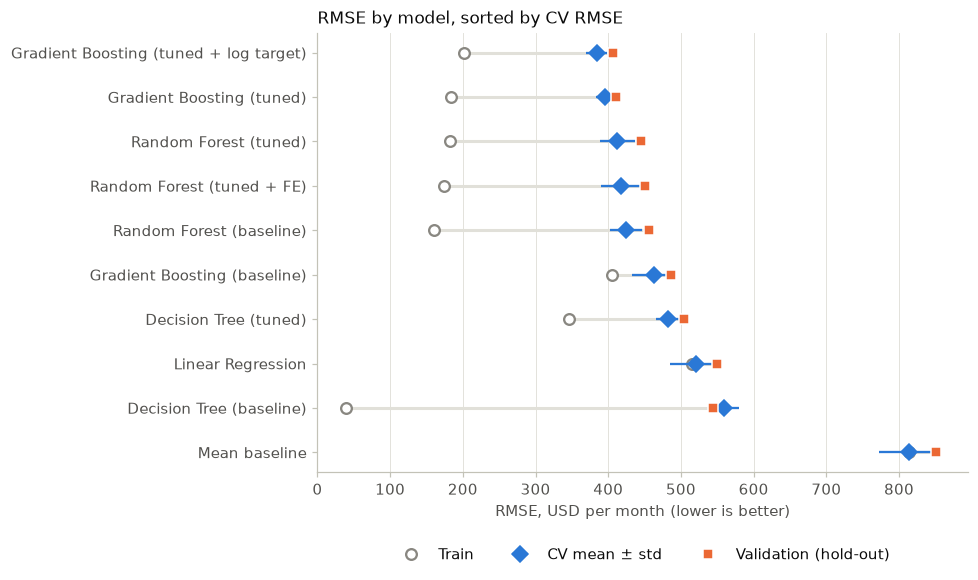

In [6]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "text.color": INK,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_2,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})

order = results.index[::-1]  # best model on top
pos = np.arange(len(order))
r = results.loc[order]

fig, ax = plt.subplots(figsize=(9, 5.4))
ax.grid(axis="y", visible=False)
ax.hlines(pos, r[["Train RMSE", "CV RMSE", "Validation RMSE"]].min(axis=1),
          r[["Train RMSE", "CV RMSE", "Validation RMSE"]].max(axis=1), color=GRID, linewidth=2, zorder=1)
ax.plot(r["Train RMSE"], pos, "o", markersize=7, markerfacecolor="white", markeredgecolor=MUTED,
        markeredgewidth=1.5, linestyle="none", label="Train", zorder=3)
ax.errorbar(r["CV RMSE"], pos, xerr=r["CV std"], fmt="D", markersize=7, color=BLUE, ecolor=BLUE,
            elinewidth=1.5, capsize=0, label="CV mean ± std", zorder=4)
ax.plot(r["Validation RMSE"], pos, "s", markersize=7, color=ORANGE, markeredgecolor="white",
        markeredgewidth=1, linestyle="none", label="Validation (hold-out)", zorder=5)
ax.set_yticks(pos, order)
ax.set_xlim(0, None)
ax.set_xlabel("RMSE, USD per month (lower is better)")
ax.set_title("RMSE by model, sorted by CV RMSE")
handles, labels = ax.get_legend_handles_labels()
legend_order = [labels.index(l) for l in ["Train", "CV mean ± std", "Validation (hold-out)"]]
ax.legend([handles[i] for i in legend_order], [labels[i] for i in legend_order],
          loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
fig.tight_layout()
plt.show()

**Observations**

- **Every model clearly beats the mean baseline** (CV RMSE 813). By CV RMSE the ranking is: Gradient Boosting (tuned + log target) 383.9, Gradient Boosting (tuned) 396.1, Random Forest (tuned) 412.5, Random Forest (tuned + FE) 417.1, Random Forest (baseline) 424.4, Gradient Boosting (baseline) 462.8, Decision Tree (tuned) 482.4, Linear Regression 520.9, Decision Tree (baseline) 559.8.
- **Validation RMSE confirms the ranking.** Only Linear Regression and the unpruned tree swap places (550.0 vs 544.2). Validation RMSE is 14 to 38 higher than CV RMSE for every model except the unpruned tree, including the mean baseline (850.9 vs 813.3). The validation rows are therefore harder to price than an average fold; this is a property of the split, not overfitting to the CV folds.
- **Reproducibility:** Linear Regression, both Decision Trees and all three Gradient Boosting models match their source notebooks exactly. Random Forest differs by at most 0.16 RMSE. The runs here are deterministic, so the difference probably comes from a different library version in the original environment; no conclusion depends on it.

**Overfitting and underfitting**

- **Decision Tree (baseline)** overfits severely: train RMSE 39 vs CV RMSE 560, the tree memorizes the training data. Pruning (tuned tree) cuts the train/CV gap from 520 to 136 and improves CV RMSE by 77.
- **Linear Regression** has almost the same train and CV RMSE (515 vs 521): no overfitting, but a high error on both, which is **underfitting** (high bias). A linear function of raw latitude, longitude and size cannot represent prices that depend on location in a non-linear way.
- **Gradient Boosting (baseline)** also underfits: 100 trees of depth 3 give train 405 and CV 463. Tuning (more and deeper trees) lowers CV RMSE by 67, and the log target by another 12.
- **Random Forest and tuned Gradient Boosting** show large train/CV gaps (about 180 to 230). For bagging this is expected, because training RMSE is measured on rows each tree has already seen. For both ensembles the errors that measure generalization, CV and validation RMSE, are the lowest of all models.

## 5. Are the differences real? Paired comparison with the best model

All candidates are scored on the same folds and the same validation rows, so they can be compared pairwise, which removes the effect of "easy" or "hard" folds:

- **CV:** the RMSE difference against the best model in each of the 5 folds (mean, standard deviation, and how many folds the best model wins).
- **Validation:** a paired bootstrap over the 1,480 validation rows (2,000 resamples). If the 95% interval of the difference excludes 0, the gap is unlikely to be luck of the split.

Positive differences mean the model is worse than the best one.

In [7]:
folds = pd.DataFrame(fold_scores, index=[f"Fold {i}" for i in range(1, 6)]).T.loc[results.index]
folds.round(1)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Model,,,,,
Gradient Boosting (tuned + log target),361.4,399.9,384.1,384.2,389.9
Gradient Boosting (tuned),379.8,400.0,406.2,409.4,384.9
Random Forest (tuned),371.4,419.6,430.6,428.5,412.5
Random Forest (tuned + FE),374.1,419.3,432.2,444.5,415.5
Random Forest (baseline),387.8,422.7,438.9,445.3,427.2
Gradient Boosting (baseline),417.6,457.9,484.4,494.0,460.1
Decision Tree (tuned),458.3,483.4,482.7,505.0,482.5
Linear Regression,474.9,516.1,533.5,572.2,508.1
Decision Tree (baseline),556.8,552.7,552.4,594.0,543.3


In [8]:
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(y_val), size=(2000, len(y_val)))
y_val_arr = y_val.to_numpy()


def boot_rmse(pred):
    return np.sqrt(((y_val_arr - pred) ** 2)[boot_idx].mean(axis=1))


best_boot = boot_rmse(val_preds[best_name])
paired_rows = []
for name in results.index.drop(best_name):
    fold_diff = np.array(fold_scores[name]) - np.array(fold_scores[best_name])
    val_diff = boot_rmse(val_preds[name]) - best_boot
    lo, hi = np.percentile(val_diff, [2.5, 97.5])
    paired_rows.append({
        "Model": name,
        "CV diff mean": fold_diff.mean(),
        "CV diff std": fold_diff.std(ddof=1),
        "Folds best wins": f"{(fold_diff > 0).sum()}/5",
        "Validation diff": results.loc[name, "Validation RMSE"] - results.loc[best_name, "Validation RMSE"],
        "Validation diff 95% CI": f"[{lo:.1f}, {hi:.1f}]",
    })

lo, hi = np.percentile(best_boot, [2.5, 97.5])
print(f"Best by CV: {best_name}")
print(f"Its validation RMSE {results.loc[best_name, 'Validation RMSE']:.1f} has a bootstrap 95% CI of [{lo:.1f}, {hi:.1f}]")
pd.DataFrame(paired_rows).set_index("Model").round(2)

Best by CV: Gradient Boosting (tuned + log target)
Its validation RMSE 405.9 has a bootstrap 95% CI of [356.2, 460.5]


,CV diff mean,CV diff std,Folds best wins,Validation diff,Validation diff 95% CI
Model,,,,,
Gradient Boosting (tuned),12.16,13.67,4/5,4.35,"[-11.5, 20.6]"
Random Forest (tuned),28.62,16.06,5/5,38.94,"[17.0, 61.1]"
Random Forest (tuned + FE),33.20,20.16,5/5,44.87,"[24.0, 66.3]"
Random Forest (baseline),40.45,16.99,5/5,50.58,"[26.2, 77.1]"
Gradient Boosting (baseline),78.89,24.71,5/5,80.79,"[56.7, 105.9]"
Decision Tree (tuned),98.46,13.77,5/5,97.77,"[65.5, 133.3]"
Linear Regression,137.03,31.98,5/5,144.02,"[113.8, 171.6]"
Decision Tree (baseline),175.90,25.59,5/5,138.30,"[97.0, 176.1]"
Mean baseline,429.38,36.83,5/5,444.93,"[392.5, 499.8]"


**Observations**

- **Gradient Boosting (tuned + log target) is significantly better than every model outside the Gradient Boosting family.** It wins all 5 folds against each of them, and the 95% interval of the validation difference excludes 0: +38.9 [17.0, 61.1] against the tuned Random Forest, +97.8 [65.5, 133.3] against the tuned Decision Tree, +144.0 [113.8, 171.6] against Linear Regression.
- **The log target gives a consistent but small gain.** Against Gradient Boosting on the raw target the difference is 12.2 on CV (better in 4 of 5 folds), while on the validation set alone the interval [-11.5, 20.6] includes 0.
- **Inside the Random Forest family** the engineered features from `03` give no gain: the tuned Random Forest without them is better.
- **One hold-out score is noisy.** The validation RMSE of the best model has a 95% interval of [356, 461] because a few expensive listings dominate the squared error. This is why model selection uses the CV mean and paired differences rather than the raw validation number.

## 6. Overfitting and underfitting: learning curves

Train and CV RMSE as the number of training rows grows, for the simplest model, the tuned single tree, the tuned Random Forest and the best model. The CV folds are the same as above.

- A **large, persistent gap** between the curves means high variance (overfitting); more data or more regularization would help.
- **Both curves high and close together** means high bias (underfitting); the model is too simple and more data will not help.

For Random Forest the train curve is computed on rows each tree mostly saw during training, so it is always low; the CV curve is what matters.

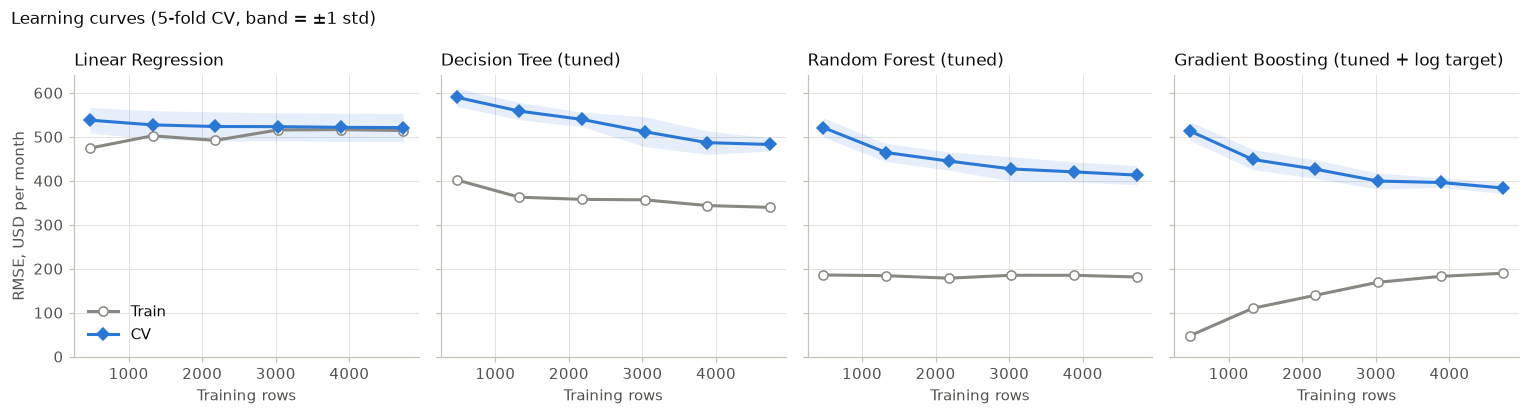

In [9]:
by_name = {c.name: c for c in candidates}
lc_models = ["Linear Regression", "Decision Tree (tuned)", "Random Forest (tuned)", best_name]

fig, axes = plt.subplots(1, len(lc_models), figsize=(14, 3.8), sharey=True)
y_max = 0
for ax, name in zip(axes, lc_models):
    c = by_name[name]
    sizes, train_scores, cv_scores = learning_curve(
        c.build(), c.features(X_train), y_train, cv=cv,
        train_sizes=np.linspace(0.1, 1.0, 6), scoring="neg_root_mean_squared_error", n_jobs=-1,
    )
    train_rmse, cv_rmse = -train_scores, -cv_scores
    ax.plot(sizes, train_rmse.mean(axis=1), "o-", color=MUTED, markerfacecolor="white",
            markersize=6, linewidth=2, label="Train")
    ax.plot(sizes, cv_rmse.mean(axis=1), "D-", color=BLUE, markersize=6, linewidth=2, label="CV")
    ax.fill_between(sizes, cv_rmse.mean(axis=1) - cv_rmse.std(axis=1),
                    cv_rmse.mean(axis=1) + cv_rmse.std(axis=1), color=BLUE, alpha=0.12, linewidth=0)
    ax.set_title(name)
    ax.set_xlabel("Training rows")
    y_max = max(y_max, (cv_rmse.mean(axis=1) + cv_rmse.std(axis=1)).max())

axes[0].set_ylim(0, y_max * 1.05)
axes[0].set_ylabel("RMSE, USD per month")
axes[0].legend(loc="lower left")
fig.suptitle("Learning curves (5-fold CV, band = ±1 std)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Observations**

- **Linear Regression:** train and CV curves meet at about 520 RMSE after roughly 3,000 rows and stay flat. This is high bias (underfitting): more data will not help, only a more flexible model or better features would.
- **Decision Tree (tuned):** a gap of about 140 between the curves remains at full size, and the CV curve is still going down. Variance dominates; even the pruned tree overfits and would benefit from more data.
- **Random Forest (tuned):** CV RMSE falls from about 520 with 10% of the rows to 413 at full size. The train curve is flat because it is measured on rows the trees have seen.
- **Gradient Boosting (tuned + log target):** CV RMSE falls from about 515 to 384, and its train RMSE rises from about 50 to 190 as the model can no longer memorize the larger training set, so the gap narrows with more data. The CV curve is still going down at full size. The final model should therefore be refit on all 7,398 labeled rows (training + validation) before predicting the test set.

## 7. Where are the errors? Error analysis by price range

The out-of-fold predictions cover all 5,918 training rows, a larger sample than the validation set. Rows are split into price quintiles (20% of listings each). RMSE squares the errors, so a few large misses on expensive listings can dominate it.

In [10]:
err_models = ["Linear Regression", "Random Forest (tuned)", best_name]
y_tr = y_train.to_numpy()
quintile = pd.qcut(y_train, 5, labels=[f"Q{i}" for i in range(1, 6)])
price_range = y_train.groupby(quintile, observed=True).agg(["min", "max"])

by_quintile = pd.DataFrame({"Price range (USD)": [f"{lo:,}-{hi:,}" for lo, hi in price_range.to_numpy()]},
                           index=price_range.index)
for name in err_models:
    err = pd.Series(oof_preds[name] - y_tr, index=y_train.index)
    by_quintile[f"RMSE: {name}"] = err.groupby(quintile, observed=True).apply(lambda e: np.sqrt((e ** 2).mean()))
best_err = pd.Series(oof_preds[best_name] - y_tr, index=y_train.index)
by_quintile[f"Mean error: {best_name}"] = best_err.groupby(quintile, observed=True).mean()

sq_err = best_err.to_numpy() ** 2
top10 = y_tr >= np.quantile(y_tr, 0.9)
print(f"{best_name}: the 10% most expensive listings produce {sq_err[top10].sum() / sq_err.sum():.0%} of the squared error")
by_quintile.round(1)

Gradient Boosting (tuned + log target): the 10% most expensive listings produce 58% of the squared error


,Price range (USD),RMSE: Linear Regression,RMSE: Random Forest (tuned),RMSE: Gradient Boosting (tuned + log target),Mean error: Gradient Boosting (tuned + log target)
price,,,,,
Q1,200-895,333.1,262.8,214.1,127.1
Q2,"896-1,145",298.5,218.0,192.6,51.2
Q3,"1,146-1,420",355.1,240.0,217.1,-6.3
Q4,"1,421-1,812",431.7,324.6,312.4,-52.7
Q5,"1,814-8,800",921.8,757.4,714.4,-240.4


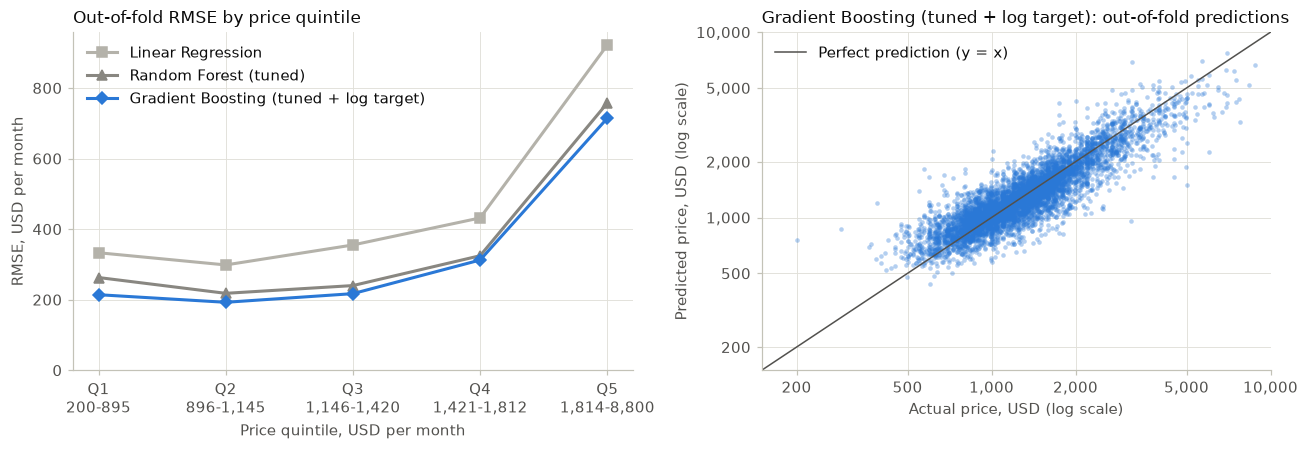

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})

# left: RMSE by quintile; best model highlighted, the other two in gray
x = np.arange(len(by_quintile))
styles = {err_models[0]: ("s", "#b4b2aa"), err_models[1]: ("^", MUTED), best_name: ("D", BLUE)}
for name in err_models:
    marker, color = styles[name]
    vals = by_quintile[f"RMSE: {name}"].to_numpy()
    ax1.plot(x, vals, marker=marker, color=color, markersize=6, linewidth=2, label=name)
ax1.set_xticks(x, [f"{q}\n{rng_}" for q, rng_ in zip(by_quintile.index, by_quintile["Price range (USD)"])])
ax1.set_xlabel("Price quintile, USD per month")
ax1.set_ylabel("RMSE, USD per month")
ax1.set_ylim(0, None)
ax1.set_title("Out-of-fold RMSE by price quintile")
ax1.legend(loc="upper left")

# right: predicted vs actual for the best model
lim = (150, 10000)
ax2.scatter(y_tr, oof_preds[best_name], s=9, color=BLUE, alpha=0.35, linewidths=0)
ax2.plot(lim, lim, color=INK_2, linewidth=1, label="Perfect prediction (y = x)")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlim(lim)
ax2.set_ylim(lim)
for axis in (ax2.xaxis, ax2.yaxis):
    axis.set_major_locator(FixedLocator([200, 500, 1000, 2000, 5000, 10000]))
    axis.set_minor_locator(NullLocator())
    axis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax2.legend(loc="upper left")
ax2.set_xlabel("Actual price, USD (log scale)")
ax2.set_ylabel("Predicted price, USD (log scale)")
ax2.set_title(f"{best_name}: out-of-fold predictions")

fig.tight_layout()
plt.show()

**Observations**

- **The error is concentrated in expensive listings.** For all three models RMSE is lowest in the middle quintiles and jumps in the top quintile (1,814 USD and above): 714 for Gradient Boosting, 757 for Random Forest and 922 for Linear Regression. For the best model, the 10% most expensive listings produce 58% of the squared error, so on this problem RMSE is driven mostly by expensive apartments.
- **The best model is better in every price range,** not only on average: Gradient Boosting has the lowest RMSE in all five quintiles.
- **Predictions are pulled toward the mean.** Gradient Boosting overpredicts the cheapest quintile by 127 on average and underpredicts the most expensive one by 240 (Random Forest: 194 and 258). The scatter plot shows the same flattening at both ends.
- **Implication for further improvement:** the models need better information about how expensive a specific location is. `06_final_model.ipynb` tests features built from the prices of nearby training listings (computed out-of-fold to avoid leakage) and ensembles of the strongest models.

## 8. Trade-offs and model selection

The best variant of each model family (by CV RMSE) against the selection criteria from the assignment: validation performance, overfitting, complexity, computational cost and interpretability.

In [12]:
interpretability = {
    "Linear Regression": "High: one coefficient per feature",
    "Decision Tree": "Medium: readable rules, but hundreds of leaves",
    "Random Forest": "Low: average of many trees, feature importances only",
    "Gradient Boosting": "Low: sum of many small trees, feature importances only",
}

family_best = results.drop(index="Mean baseline").groupby("Family")["CV RMSE"].idxmin()
tradeoffs = results.loc[family_best.to_numpy(),
                        ["CV RMSE", "CV std", "Validation RMSE", "Gap (Val - Train)", "Fit time (s)", "Complexity"]]
tradeoffs["Interpretability"] = results.loc[tradeoffs.index, "Family"].map(interpretability)
tradeoffs.sort_values("CV RMSE").round(2)

,CV RMSE,CV std,Validation RMSE,Gap (Val - Train),Fit time (s),Complexity,Interpretability
Model,,,,,,,
Gradient Boosting (tuned + log target),383.91,14.12,405.94,204.18,2.58,"1000 trees, 19,710 leaves","Low: sum of many small trees, feature importan..."
Random Forest (tuned),412.53,24.13,444.88,263.01,0.66,"400 trees, 943,409 leaves","Low: average of many trees, feature importance..."
Decision Tree (tuned),482.37,16.53,503.72,157.27,0.02,"1 tree, 356 leaves","Medium: readable rules, but hundreds of leaves"
Linear Regression,520.94,35.69,549.97,34.96,0.01,61 coefficients,High: one coefficient per feature


**Best of the team's models: Gradient Boosting (tuned + log target)** (`04`: 1000 trees, `learning_rate=0.1`, `max_depth=5`, `min_samples_leaf=5`, `subsample=0.8`, `max_features=0.5`, trained on `log(price)`).

- **Validation performance:** lowest CV RMSE (383.9 ± 14.1, also the most stable across folds among the top models) and lowest validation RMSE (405.9, MAE 240.0, R² 0.77). It is significantly better than every model outside its family, and better than the raw-target version in 4 of 5 folds.
- **Overfitting:** train RMSE (202) is well below CV, but the learning curve shows the gap narrowing with more data, and the boosting-stage curve in `04` shows that additional trees do not increase the CV error. The validation set confirms the CV estimate.
- **Complexity and computational cost:** 1000 trees with about 20 thousand leaves in total, far fewer than the tuned Random Forest (about 0.94 million). It fits in about 3 seconds on 5,918 rows, which is not a constraint at this data size.
- **Interpretability:** low compared to Linear Regression or a single tree; feature importances (`04`) give partial insight. The competition objective is RMSE, so this trade-off is acceptable.
- **Against the raw-target Gradient Boosting:** same complexity and cost, consistently lower CV error, so there is no reason to prefer the raw target.

This model is the starting point of `06_final_model.ipynb`, which adds neighborhood features and ensembles and selects the model used for `predictions.csv` with the same rule: lowest CV RMSE, and the simpler model when the difference is not significant.

## 9. Save results

`results/model_comparison.csv` holds every candidate with one set of columns, so it replaces the per-model files for the README table.

In [13]:
out = results[summary_cols].round(2).reset_index()
out.insert(2, "Source notebook", out["Model"].map({c.name: c.source for c in candidates}))

Path("../results").mkdir(exist_ok=True)
out.to_csv("../results/model_comparison.csv", index=False)
out[["Model", "Source notebook", "CV RMSE", "Validation RMSE"]]

,Model,Source notebook,CV RMSE,Validation RMSE
0,Gradient Boosting (tuned + log target),04_gradient_boosting,383.91,405.94
1,Gradient Boosting (tuned),04_gradient_boosting,396.07,410.29
2,Random Forest (tuned),03_random_forest,412.53,444.88
3,Random Forest (tuned + FE),03_random_forest,417.12,450.81
4,Random Forest (baseline),03_random_forest,424.36,456.52
5,Gradient Boosting (baseline),04_gradient_boosting,462.80,486.73
6,Decision Tree (tuned),02_decision_tree,482.37,503.72
7,Linear Regression,01_data_preprocessing,520.94,549.97
8,Decision Tree (baseline),02_decision_tree,559.81,544.24
9,Mean baseline,05_model_comparison,813.29,850.87
